# MIT–BIT charging-rate switch replay

Forecast operational SOH and delivered energy over the next five recorded aging cycles. Compare persistence, rate-only Ridge and history-aware Ridge on held-out cells. Replay representative and high-error 2C↔3C switches under the measured charge schedule.

Open from the LifeGuard-RL project and use its Python kernel. The input is the publisher's extracted MIT–BIT v3 tree under Dataset/MIT-BIT, or its ZIP. Preserve the #cell directory names. Set MODE to pilot for the two-cell audit. Benchmark mode audits the pilot cells first, then uses the available randomized workbooks and reports coverage. The notebook and model run on one CPU thread.

[Publisher dataset and protocol](https://data.mendeley.com/datasets/kw34hhw7xg/3)

In [1]:
import os
for name in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[name] = "1"

import json
import re
from collections import defaultdict
from contextlib import contextmanager
from pathlib import Path, PurePosixPath
from tempfile import SpooledTemporaryFile
from xml.etree import ElementTree
from zipfile import ZIP_DEFLATED, ZipFile

import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
from threadpoolctl import threadpool_limits

DATASET_PATH = None  # Extracted publisher tree or official dataset ZIP.
OUTPUT_ROOT = None
MODE = "benchmark"  # Use "pilot" to audit the two verified example cells.
DOI = "10.17632/kw34hhw7xg.3"
OUTPUT_NAME = "lifeguard_mit_bit_switch_replay_results"
PILOTS = (1, 3)
NOMINAL_AH = 2.4
BLOCK = 5
RATES = (1, 2, 3)
ALPHAS = (1, 10, 100)
SEED = 42
FIXED_IDS = {2, 6, 10, 13, 16, 19, 22, 23, 26, 29, 32, 35, 38, 41, 44, 45, 48, 49, 52, 53, 57, 58}
EXPECTED = set(range(1, 78)) - FIXED_IDS

cwd = Path.cwd()
project = next((p for p in (cwd, *cwd.parents)
                if (p / "README_LifeGuard_RL.md").is_file() and (p / "reports").is_dir()), None)
if project is None:
    raise FileNotFoundError("Open this notebook from within the LifeGuard-RL project.")
source = Path(DATASET_PATH).expanduser() if DATASET_PATH else project / "Dataset" / "MIT-BIT"
if DATASET_PATH is None and not source.is_dir():
    source = source.with_suffix(".zip")
output = (Path(OUTPUT_ROOT).expanduser() if OUTPUT_ROOT else project / "reports") / (OUTPUT_NAME + ("_pilot" if MODE == "pilot" else ""))
if MODE not in {"pilot", "benchmark"}:
    raise ValueError('Use MODE = "pilot" or "benchmark".')

## Audit the aging workbooks

Exclude conditioning workbooks and the initial discharge-only boundary in the aging workbook. Keep gaps in the five-cycle grid. Classify charge rates from the measured constant-current values and use only ordinary 3C discharges ending near 3.0 V. Integrate discharge energy from timestamped voltage and current, compare it with the recorder's energy counter and record any unavailable energy separately. In the two pilot files, ordinary aging starts at raw cycle 2.

In [2]:
SHEET = "xl/worksheets/sheet1.xml"
HEADERS = ("Data_Point", "Test_Time(s)", "Current(A)", "Capacity(Ah)", "Voltage(V)",
           "Energy(Wh)", "Temperature(℃)", "Date_Time", "Cycle_Index")
FIELDS = b"CDEFHI"
CELL_VALUE = re.compile(rb'<c r="([A-I])(\d+)"[^>]*><v>([^<]*)</v></c>')
NUMERIC = re.compile(rb"[+\-0-9.Ee]+")
STRING = re.compile(rb"<si(?:\s[^>]*)?>.*?</si>", re.DOTALL)


@contextmanager
def aging_workbooks(path):
    archive = ZipFile(path) if path.is_file() else None
    try:
        if archive is not None:
            files = archive.namelist()
        elif path.is_dir():
            files = [file.relative_to(path).as_posix() for file in path.rglob("*.xlsx")]
        else:
            raise FileNotFoundError(f"Place MIT–BIT v3 in {path} or set DATASET_PATH.")
        found = defaultdict(list)
        for file in files:
            rel = PurePosixPath(file)
            if rel.suffix.lower() != ".xlsx" or "_cycles" not in rel.name.lower() or rel.name.startswith("~$"):
                continue
            cell = next((int(part[1:]) for part in reversed(rel.parts[:-1])
                         if re.fullmatch(r"#\d+", part)), None)
            if cell in EXPECTED:
                found[cell].append(file)
        if not found:
            raise ValueError("No MIT–BIT randomized aging workbooks found. Preserve the publisher's #cell folders.")
        yield archive, found
    finally:
        if archive is not None:
            archive.close()


def validate_header(workbook, row):
    entries = CELL_VALUE.findall(row)
    if len(entries) != len(HEADERS):
        raise ValueError("Unexpected MIT–BIT worksheet header layout.")
    table = workbook.read("xl/sharedStrings.xml")
    wanted = {int(value) for _, _, value in entries}
    labels = {}
    for index, match in enumerate(STRING.finditer(table)):
        if index in wanted:
            labels[index] = "".join(ElementTree.fromstring(match[0]).itertext())
            if len(labels) == len(wanted):
                break
    if tuple(labels.get(int(value)) for _, _, value in entries) != HEADERS:
        raise ValueError("Unexpected MIT–BIT worksheet columns or units.")


def trace_chunks(workbook):
    # Stream the verified worksheet instead of building a workbook object with millions of cells.
    with workbook.open(SHEET) as xml:
        pending = xml.read(2**20)
        header_end = pending.find(b"</row>")
        if header_end < 0:
            raise ValueError("Missing worksheet header.")
        validate_header(workbook, pending[:header_end])
        pending = pending[header_end + len(b"</row>"):]
        while pending:
            cutoff = pending.rfind(b"</row>")
            if cutoff < 0:
                if b"</sheetData>" in pending:
                    break
                chunk = xml.read(2**20)
                if not chunk:
                    raise ValueError("Incomplete worksheet XML.")
                pending += chunk
                continue
            cutoff += len(b"</row>")
            complete, pending = pending[:cutoff], pending[cutoff:]
            values = [(col, value) for col, _, value in CELL_VALUE.findall(complete)
                      if col[0] in FIELDS]
            rows = complete.count(b"</row>")
            if (len(values) != rows * len(FIELDS)
                    or any(col[0] != FIELDS[i % len(FIELDS)] or not NUMERIC.fullmatch(value)
                           for i, (col, value) in enumerate(values))):
                raise ValueError("Incomplete numeric fields or reordered columns in the aging worksheet.")
            sample = np.fromstring(b" ".join(value for _, value in values), sep=" ").reshape(-1, len(FIELDS))
            yield sample
            pending += xml.read(2**20)


def cycle_traces(workbook):
    carry = np.empty((0, len(FIELDS)))
    previous = 0
    for chunk in trace_chunks(workbook):
        data = np.concatenate((carry, chunk))
        split = np.flatnonzero(data[:-1, -1] != data[1:, -1]) + 1
        groups = np.split(data, split)
        for trace in groups[:-1]:
            raw = trace[0, -1]
            if raw <= previous or raw != int(raw):
                raise ValueError("Repeated or unordered raw cycle index.")
            previous = int(raw)
            yield previous, trace
        carry = groups[-1]
    if carry.size:
        raw = carry[0, -1]
        if raw <= previous or raw != int(raw):
            raise ValueError("Repeated or unordered final cycle index.")
        yield int(raw), carry


def integrate_discharge(seconds, current, voltage):
    # Recorder timestamps have occasional one-second reversals. The running maximum
    # combines coincident readings without counting the same time interval twice.
    if np.any(np.diff(seconds) < -1.1):
        return np.nan, np.nan
    delta = np.diff(np.maximum.accumulate(seconds))
    if np.any(delta > 30):
        return np.nan, np.nan
    return (float(np.dot(delta, -current[:-1] - current[1:]) / 7200),
            float(np.dot(delta, -current[:-1] * voltage[:-1] - current[1:] * voltage[1:]) / 7200))


def audit_trace(cell, raw, trace):
    current, capacity, voltage, energy, date_days, _ = trace.T
    record = dict(cell_id=cell, raw_cycle=raw, aging_cycle=raw - 1, charge_rate_c=None,
                  cc_current_a=None, discharge_current_a=None, capacity_ah=None, delivered_wh=None,
                  meter_wh=None, integrated_ah=None, energy_status="missing_complete_discharge")
    if not np.isfinite(trace).all():
        record["energy_status"] = "invalid_trace"
        return record
    negative = np.flatnonzero(current < -0.1)
    charge = current[:negative[0]] if len(negative) else current
    positive = charge[charge > 0.1]
    if positive.size >= 5:
        amps = float(np.quantile(positive, 0.9))
        record["cc_current_a"] = amps
        record["charge_rate_c"] = next(
            (rate for rate in RATES
             if abs(amps - rate * NOMINAL_AH) <= 0.05 * rate * NOMINAL_AH
             and np.sum(abs(positive - rate * NOMINAL_AH) <= 0.05 * rate * NOMINAL_AH) >= 5), None)
    if negative.size < 2:
        return record
    discharge = current[negative]
    amps = float(np.median(discharge))
    record["discharge_current_a"] = amps
    if (abs(amps + 3 * NOMINAL_AH) > 0.05 * 3 * NOMINAL_AH
            or abs(voltage[negative[-1]] - 3.0) > 0.09 or np.any(np.diff(negative) != 1)):
        record["energy_status"] = "off_protocol_discharge"
        return record
    q_meter, wh_meter = float(capacity[negative].max()), float(energy[negative].max())
    if q_meter <= 0:
        return record
    record.update(capacity_ah=q_meter, meter_wh=wh_meter)
    time = (date_days[negative] - date_days[negative[0]]) * 86400
    q, wh = integrate_discharge(time, discharge, voltage[negative])
    record["integrated_ah"] = q
    if not np.isfinite(wh) or wh <= 0:
        record["energy_status"] = "invalid_timestamps"
    elif abs(q - q_meter) > max(0.02, 0.01 * q_meter) or abs(wh - wh_meter) > max(0.10, 0.015 * wh_meter):
        record["energy_status"] = "meter_disagreement"
    else:
        record.update(delivered_wh=wh, energy_status="ok")
    return record


def read_cell(archive, file, cell):
    if archive is None:
        with ZipFile(source / file) as workbook:
            return [audit_trace(cell, raw, trace) for raw, trace in cycle_traces(workbook)]
    # Nested XLSX files need a seekable stream. Spool larger workbooks to disk, one at a time.
    with archive.open(file) as compressed, SpooledTemporaryFile(max_size=4 * 2**20) as stream:
        while chunk := compressed.read(2**20):
            stream.write(chunk)
        stream.seek(0)
        with ZipFile(stream) as workbook:
            return [audit_trace(cell, raw, trace) for raw, trace in cycle_traces(workbook)]


def make_blocks(rows):
    trace = pd.DataFrame(rows).set_index("aging_cycle", verify_integrity=True)
    positive = trace.loc[trace.index >= 1]
    early = positive.capacity_ah.dropna().head(BLOCK)
    reference = float(early.median()) if len(early) == BLOCK else np.nan
    reference_ready = int(early.index[-1]) if len(early) == BLOCK else np.inf
    blocks = []
    for start in range(1, int(positive.index.max()) + 1, BLOCK):
        part = positive.reindex(range(start, start + BLOCK))
        rates = part.charge_rate_c.dropna().unique()
        rate = int(rates[0]) if len(rates) == 1 and part.charge_rate_c.notna().all() else None
        capacity_ok = bool(part.capacity_ah.notna().all() and start + BLOCK - 1 >= reference_ready)
        energy_ok = bool(part.delivered_wh.notna().all())
        status = ("missing_cycles" if part.cell_id.isna().any() else "unverified_rate" if rate is None
                  else "missing_capacity" if not capacity_ok else "ok")
        blocks.append(dict(cell_id=rows[0]["cell_id"], start_cycle=start, end_cycle=start + BLOCK - 1,
                           charge_rate_c=rate, reference_ah=reference, status=status,
                           observed_soh_pct=float(100 * part.capacity_ah.median() / reference) if capacity_ok else np.nan,
                           observed_wh=float(part.delivered_wh.sum()) if energy_ok else np.nan))
    return blocks


def audit_source():
    cycles, blocks, manifest = [], [], []
    with aging_workbooks(source) as (archive, found):
        requested = PILOTS if MODE == "pilot" else (*PILOTS, *sorted(EXPECTED - set(PILOTS)))
        for cell in requested:
            files = found.get(cell, [])
            if len(files) != 1:
                manifest.append((cell, "|".join(files), "missing" if not files else "multiple_workbooks", "", 0))
                continue
            try:
                rows = read_cell(archive, files[0], cell)
                if (not rows or rows[0]["raw_cycle"] != 1 or rows[0]["charge_rate_c"] is not None
                        or rows[1]["raw_cycle"] != 2):
                    raise ValueError("Expected the publisher's discharge-only boundary at raw cycle 1.")
                events = make_blocks(rows)
            except (ValueError, KeyError, OSError) as error:
                manifest.append((cell, files[0], "unreadable", str(error), 0))
                continue
            cycles.extend(rows)
            blocks.extend(events)
            count = sum(row["status"] == "ok" for row in events)
            manifest.append((cell, files[0], "read", "", count))
            if cell in PILOTS:
                verified = [b["charge_rate_c"] if b["status"] == "ok" else None for b in events]
                transitions = set(zip(verified[:-1], verified[1:]))
                if not {(2, 3), (3, 2)}.issubset(transitions):
                    raise ValueError(f"Pilot cell #{cell} failed the recorded switch and block alignment check.")
                print(f"Pilot #{cell}: {count} verified blocks, both 2C↔3C directions")
    return pd.DataFrame(cycles), pd.DataFrame(blocks), pd.DataFrame(
        manifest, columns=["cell_id", "workbook", "status", "detail", "verified_blocks"])


np.testing.assert_allclose(integrate_discharge(np.arange(0, 361, 30), np.full(13, -2), np.full(13, 3.5)),
                           (0.2, 0.7))
with threadpool_limits(limits=1):
    cycle_audit, block_audit, source_audit = audit_source()
print(f"Read {source_audit.status.eq('read').sum()} randomized cells; "
      f"{source_audit.status.ne('read').sum()} requested inputs unavailable or unreadable.")

Pilot #1: 19 verified blocks, both 2C↔3C directions
Pilot #3: 19 verified blocks, both 2C↔3C directions
Read 55 randomized cells; 0 requested inputs unavailable or unreadable.


## Replay five-cycle blocks on held-out cells

Predict at the end of a completed block, using its measured SOH and the upcoming recorded rate. The history model also uses the previous rate and the difference between the last two completed blocks. Separate outcomes and prediction coverage are reported for SOH and Wh. The outer split holds out entire cells. Selection uses only inner-fold results.

In [3]:
MODELS = ("persistence", "rate_only", "history_aware")
DISPLAY_MODELS = {"persistence": "Persistence", "rate_only": "Rate-only Ridge",
                  "history_aware": "History-aware Ridge"}
TARGETS = {"soh": ("observed_soh_pct", "start_soh_pct"),
           "wh": ("observed_wh", "start_wh")}
SWITCHES = {"2-to-3": (2, 3), "3-to-2": (3, 2)}
PARTITIONS = ("all", *SWITCHES, "same-rate", "other-switch")


def prediction_rows(blocks):
    records = []
    for cell, trace in blocks.groupby("cell_id"):
        index = trace.set_index("start_cycle", verify_integrity=True)
        for row in trace.loc[trace.charge_rate_c.notna()].itertuples(index=False):
            start = row.start_cycle
            if start - BLOCK not in index.index or start - 2 * BLOCK not in index.index:
                continue
            previous, older = index.loc[start - BLOCK], index.loc[start - 2 * BLOCK]
            if previous.status != "ok" or older.status != "ok":
                continue
            before, after = int(previous.charge_rate_c), int(row.charge_rate_c)
            direction = next((name for name, pair in SWITCHES.items() if pair == (before, after)),
                             "same-rate" if before == after else "other-switch")
            records.append(dict(cell_id=cell, start_cycle=start, end_cycle=row.end_cycle, direction=direction,
                                previous_rate_c=before, charge_rate_c=after, start_soh_pct=previous.observed_soh_pct,
                                start_wh=previous.observed_wh, recent_delta_pp=previous.observed_soh_pct - older.observed_soh_pct,
                                observed_soh_pct=row.observed_soh_pct, observed_wh=row.observed_wh))
    return pd.DataFrame(records)


def eligible(rows, target):
    actual, prior = TARGETS[target]
    return rows[actual].notna() & rows[prior].notna()


def features(rows, model):
    x = [rows.start_soh_pct.to_numpy(), rows.charge_rate_c.eq(2).to_numpy(), rows.charge_rate_c.eq(3).to_numpy()]
    if model == "history_aware":
        x += [rows.previous_rate_c.eq(2).to_numpy(), rows.previous_rate_c.eq(3).to_numpy(),
              rows.recent_delta_pp.to_numpy()]
    return np.column_stack(x)


def model_predict(train, test, target, model, alpha):
    actual, prior = TARGETS[target]
    baseline = test[prior].to_numpy()
    if model == "persistence":
        return baseline
    training = train.loc[eligible(train, target)]
    x = features(training, model)
    weights = 1 / training.groupby("cell_id").cell_id.transform("size").to_numpy(dtype=float)
    weights /= weights.mean()
    center = np.average(x, axis=0, weights=weights)
    scale = np.sqrt(np.average((x - center)**2, axis=0, weights=weights))
    scale[scale < 1e-9] = 1
    y = training[actual].to_numpy()
    if target == "soh":
        y = y - training[prior].to_numpy()
    reg = Ridge(alpha=alpha)
    reg.fit((x - center) / scale, y, sample_weight=weights)
    fit = reg.predict((features(test, model) - center) / scale)
    return baseline + fit if target == "soh" else np.maximum(0, fit)


def inner_selection(train, target, outer_fold):
    candidates = [(MODELS[0], 0), *((model, alpha) for model in MODELS[1:] for alpha in ALPHAS)]
    cells = np.sort(train.cell_id.unique())
    splits = KFold(n_splits=3, shuffle=True, random_state=SEED)
    held_out = defaultdict(list)
    actual, _ = TARGETS[target]
    for a, b in splits.split(cells):
        fit = train.loc[train.cell_id.isin(cells[a])]
        check = train.loc[train.cell_id.isin(cells[b]) & eligible(train, target)]
        if check.empty:
            continue
        for model, alpha in candidates:
            error = abs(model_predict(fit, check, target, model, alpha) - check[actual])
            held_out[model, alpha].append(pd.DataFrame({
                "cell_id": check.cell_id, "direction": check.direction, "error": error,
            }))
    scores = {}
    for candidate in candidates:
        if not held_out[candidate]:
            raise ValueError(f"Insufficient inner validation labels for {target} in fold {outer_fold}.")
        scored = pd.concat(held_out[candidate], ignore_index=True)
        switches = scored.loc[scored.direction.isin(SWITCHES)]
        reference = switches if len(switches) else scored
        scores[candidate] = reference.groupby("cell_id").error.mean().mean()
    key = lambda candidate: (scores[candidate], MODELS.index(candidate[0]), -candidate[1])
    per_model = {model: min((item for item in candidates if item[0] == model), key=key) for model in MODELS}
    chosen = min(per_model.values(), key=key)
    selection = [dict(fold=outer_fold, target=target, model=model, alpha=alpha,
                      inner_mae=scores[model, alpha], tuned=(model, alpha) == per_model[model],
                      displayed=(model, alpha) == chosen) for model, alpha in candidates]
    return per_model, chosen, selection


def evaluate(rows):
    cells = np.sort(rows.cell_id.unique())
    if len(cells) < 5:
        raise ValueError("The five-fold benchmark needs at least five eligible randomized batteries.")
    output, selection, splits = [], [], []
    outer = KFold(n_splits=5, shuffle=True, random_state=SEED)
    for fold, (a, b) in enumerate(outer.split(cells), 1):
        train = rows.loc[rows.cell_id.isin(cells[a])]
        test = rows.loc[rows.cell_id.isin(cells[b])].copy()
        splits.extend((fold, cell, "train" if cell in cells[a] else "test") for cell in cells)
        test["fold"] = fold
        for target in TARGETS:
            per_model, chosen, tuned = inner_selection(train, target, fold)
            selection.extend(tuned)
            for name, (model, alpha) in per_model.items():
                test[f"{target}_{name}"] = model_predict(train, test, target, model, alpha)
            test[f"predicted_{target}"] = test[f"{target}_{chosen[0]}"]
            test[f"{target}_model"] = chosen[0]
        output.append(test)
    predictions = pd.concat(output, ignore_index=True).sort_values(["cell_id", "start_cycle"])
    if predictions.duplicated(["cell_id", "start_cycle"]).any():
        raise ValueError("Duplicate held-out predictions.")
    return predictions, pd.DataFrame(selection), pd.DataFrame(splits, columns=["fold", "cell_id", "role"])


def metrics_for(predictions):
    metrics = []
    for partition in PARTITIONS:
        rows = predictions if partition == "all" else predictions.loc[predictions.direction.eq(partition)]
        for target, (actual, _) in TARGETS.items():
            paired = rows.loc[eligible(rows, target)]
            for model in (*MODELS, "selected"):
                column = f"predicted_{target}" if model == "selected" else f"{target}_{model}"
                error = paired[column] - paired[actual]
                worst = error.abs().idxmax() if len(error) else None
                metrics.append(dict(direction=partition, target=target, model=model, eligible_blocks=len(rows),
                                    scored_blocks=len(paired), scored_cells=paired.cell_id.nunique(),
                                    mae=error.abs().groupby(paired.cell_id).mean().mean(),
                                    worst_error=error.abs().max(),
                                    signed_bias=error.groupby(paired.cell_id).mean().mean(),
                                    worst_cell=paired.loc[worst, "cell_id"] if worst is not None else None,
                                    worst_start_cycle=paired.loc[worst, "start_cycle"] if worst is not None else None))
    return pd.DataFrame(metrics)


REPLAY_FIELDS = ["cell_id", "fold", "start_cycle", "end_cycle", "direction", "previous_rate_c", "charge_rate_c",
                 "start_soh_pct", "start_wh", "observed_soh_pct", "observed_wh", "predicted_soh", "predicted_wh",
                 "soh_model", "wh_model"]


def make_replays(predictions):
    cases, blocks = [], []
    for direction in SWITCHES:
        matched = predictions.loc[predictions.direction.eq(direction) & predictions.observed_soh_pct.notna()].copy()
        if matched.empty:
            continue
        matched["error"] = abs(matched.predicted_soh - matched.observed_soh_pct)
        matched["from_median"] = abs(matched.error - matched.error.median())
        worst = matched.sort_values(["error", "cell_id", "start_cycle"], ascending=[False, True, True]).iloc[0]
        remaining = matched.drop(index=worst.name) if len(matched) > 1 else matched
        typical = remaining.sort_values(["from_median", "cell_id", "start_cycle"]).iloc[0]
        for name, row in (("typical", typical), ("worst", worst)):
            if name == "worst" and len(matched) == 1:
                continue
            key = f"{direction}-{name}"
            cell, focus = int(row.cell_id), int(row.start_cycle)
            cases.append(dict(case_id=key, direction=direction, kind=name, cell_id=cell,
                              focus_start_cycle=focus, focus_soh_error_pp=row.error))
            per_cell = predictions.loc[predictions.cell_id.eq(cell)].set_index("start_cycle", drop=False)
            interval = [focus]
            for sign in (-1, 1):
                for ahead in (1, 2):
                    point = focus + sign * ahead * BLOCK
                    if point not in per_cell.index:
                        break
                    interval.append(point)
            for record in per_cell.loc[sorted(interval), REPLAY_FIELDS].to_dict("records"):
                blocks.append({"case_id": key, **record})
    return pd.DataFrame(cases), pd.DataFrame(blocks)


if MODE == "benchmark":
    events = prediction_rows(block_audit)
    with threadpool_limits(limits=1):
        predictions, selection, cell_splits = evaluate(events)
    metrics = metrics_for(predictions)
    cases, replay_blocks = make_replays(predictions)
    if set(cases.direction) != set(SWITCHES):
        raise ValueError("Both recorded switch directions are required for the replay.")
    print(f"Scored {len(predictions)} held-out blocks from {predictions.cell_id.nunique()} cells.")

Scored 990 held-out blocks from 55 cells.


# MIT–BIT charging-rate switch replay

MIT–BIT v3, DOI 10.17632/kw34hhw7xg.3. Run mode benchmark. Read 55 of 55 requested randomized workbooks. The 55-cell publisher cohort is the coverage reference.

The aging workbooks start with a discharge-only boundary at raw cycle 1. The block clock starts at raw cycle 2. Operational SOH normalizes median block capacity to the median of the first five complete aging discharges. It describes capacity available under the recorded 3C discharge. The effect of a switch on this measurement can include short-term changes in available capacity.

The audit found 5,555 raw cycles, 1,045 verified complete blocks and 5,493 meter-checked cycle energy estimates.

## Held-out forecast errors

Five battery-level folds evaluated 55 cells. Tuning and model choice used only the training cells of each fold. The earlier block provides the measured initial condition. Each row reports cell-weighted mean absolute error (MAE) and maximum absolute error. Bias is forecast minus measured.

| Recorded transition | Target | Model | MAE | Max | Bias | Scored / eligible | Worst cell / start |
| --- | --- | --- | ---: | ---: | ---: | ---: | --- |
| all | SOH pp | Persistence | 18.697 | 77.290 | +2.809 | 935/990 | #77 / 11 |
| all | SOH pp | Rate-only Ridge | 9.110 | 63.587 | +0.021 | 935/990 | #77 / 26 |
| all | SOH pp | History-aware Ridge | 3.790 | 40.847 | +0.026 | 935/990 | #77 / 26 |
| all | SOH pp | Fold-selected | 3.790 | 40.847 | +0.026 | 935/990 | #77 / 26 |
| all | Wh | Persistence | 5.142 | 13.971 | +0.755 | 923/990 | #77 / 11 |
| all | Wh | Rate-only Ridge | 2.696 | 11.507 | +0.006 | 923/990 | #77 / 91 |
| all | Wh | History-aware Ridge | 2.294 | 13.352 | +0.016 | 923/990 | #77 / 56 |
| all | Wh | Fold-selected | 2.294 | 13.352 | +0.016 | 923/990 | #77 / 56 |
| 2-to-3 | SOH pp | Persistence | 24.625 | 42.398 | +24.625 | 98/100 | #77 / 36 |
| 2-to-3 | SOH pp | Rate-only Ridge | 6.026 | 13.744 | -0.052 | 98/100 | #4 / 11 |
| 2-to-3 | SOH pp | History-aware Ridge | 3.873 | 19.251 | -0.497 | 98/100 | #77 / 36 |
| 2-to-3 | SOH pp | Fold-selected | 3.873 | 19.251 | -0.497 | 98/100 | #77 / 36 |
| 2-to-3 | Wh | Persistence | 6.675 | 8.250 | +6.675 | 96/100 | #75 / 31 |
| 2-to-3 | Wh | Rate-only Ridge | 3.086 | 8.995 | -0.735 | 96/100 | #9 / 16 |
| 2-to-3 | Wh | History-aware Ridge | 2.659 | 9.768 | -0.595 | 96/100 | #77 / 36 |
| 2-to-3 | Wh | Fold-selected | 2.659 | 9.768 | -0.595 | 96/100 | #77 / 36 |
| 3-to-2 | SOH pp | Persistence | 15.959 | 29.463 | -15.959 | 122/125 | #65 / 76 |
| 3-to-2 | SOH pp | Rate-only Ridge | 8.522 | 34.989 | -8.169 | 122/125 | #76 / 16 |
| 3-to-2 | SOH pp | History-aware Ridge | 3.006 | 11.282 | +0.630 | 122/125 | #65 / 76 |
| 3-to-2 | SOH pp | Fold-selected | 3.006 | 11.282 | +0.630 | 122/125 | #65 / 76 |
| 3-to-2 | Wh | Persistence | 4.336 | 6.398 | -4.336 | 122/125 | #65 / 76 |
| 3-to-2 | Wh | Rate-only Ridge | 2.533 | 7.236 | -1.622 | 122/125 | #61 / 11 |
| 3-to-2 | Wh | History-aware Ridge | 2.020 | 7.315 | -0.013 | 122/125 | #77 / 76 |
| 3-to-2 | Wh | Fold-selected | 2.020 | 7.315 | -0.013 | 122/125 | #77 / 76 |
| same-rate | SOH pp | Persistence | 2.984 | 11.459 | +2.509 | 297/325 | #56 / 21 |
| same-rate | SOH pp | Rate-only Ridge | 7.285 | 18.904 | +1.685 | 297/325 | #55 / 21 |
| same-rate | SOH pp | History-aware Ridge | 1.883 | 9.932 | +0.310 | 297/325 | #77 / 46 |
| same-rate | SOH pp | Fold-selected | 1.883 | 9.932 | +0.310 | 297/325 | #77 / 46 |
| same-rate | Wh | Persistence | 0.844 | 2.872 | +0.720 | 291/325 | #56 / 21 |
| same-rate | Wh | Rate-only Ridge | 2.546 | 9.117 | +0.538 | 291/325 | #77 / 86 |
| same-rate | Wh | History-aware Ridge | 2.221 | 10.734 | +0.241 | 291/325 | #77 / 51 |
| same-rate | Wh | Fold-selected | 2.221 | 10.734 | +0.241 | 291/325 | #77 / 51 |
| other-switch | SOH pp | Persistence | 29.060 | 77.290 | +3.249 | 418/440 | #77 / 11 |
| other-switch | SOH pp | Rate-only Ridge | 11.253 | 63.587 | +1.230 | 418/440 | #77 / 26 |
| other-switch | SOH pp | History-aware Ridge | 5.094 | 40.847 | -0.355 | 418/440 | #77 / 26 |
| other-switch | SOH pp | Fold-selected | 5.094 | 40.847 | -0.355 | 418/440 | #77 / 26 |
| other-switch | Wh | Persistence | 8.027 | 13.971 | +0.872 | 414/440 | #77 / 11 |
| other-switch | Wh | Rate-only Ridge | 2.854 | 11.507 | +0.405 | 414/440 | #77 / 91 |
| other-switch | Wh | History-aware Ridge | 2.358 | 13.352 | +0.096 | 414/440 | #77 / 56 |
| other-switch | Wh | Fold-selected | 2.358 | 13.352 | +0.096 | 414/440 | #77 / 56 |

## History effect and examples

- 2-to-3, SOH history-aware MAE changed by -2.153 pp relative to rate-only Ridge.
- 2-to-3, WH history-aware MAE changed by -0.427 Wh relative to rate-only Ridge.
- 3-to-2, SOH history-aware MAE changed by -5.516 pp relative to rate-only Ridge.
- 3-to-2, WH history-aware MAE changed by -0.513 Wh relative to rate-only Ridge.

The replay includes an example nearest the median held-out SOH error and the largest SOH error for each switch direction. It displays forecasts under the recorded action sequence. Controller benefits and alternative charge schedules require separate evaluation.


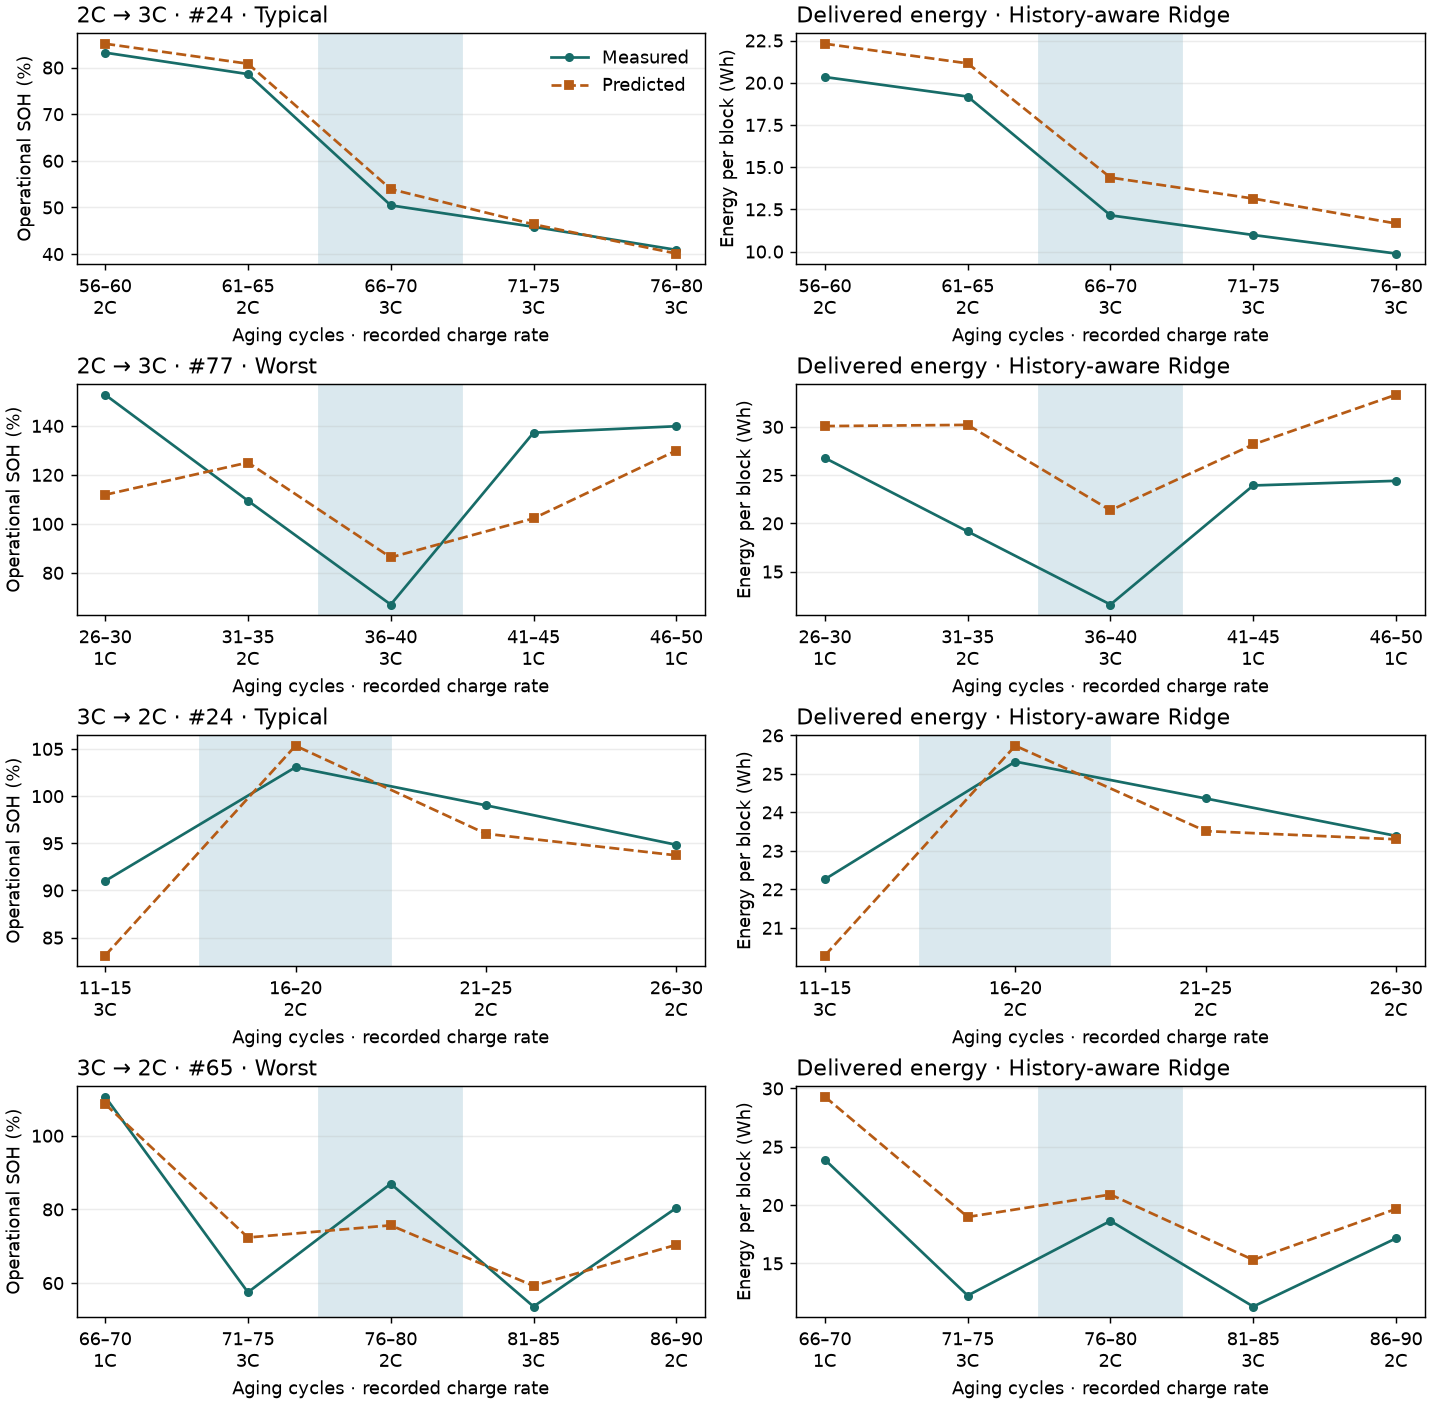

Saved /Users/sakibsmacbookm5/Documents/Python work/research-project/SICIP Final Project/reports/lifeguard_mit_bit_switch_replay_results.zip


In [4]:
def draw_replays(path):
    import matplotlib.pyplot as plt

    figure, axes = plt.subplots(len(cases), 2, figsize=(11, 2.7 * len(cases)), squeeze=False,
                                layout="constrained")
    for (a, b), case in zip(axes, cases.itertuples(index=False)):
        group = replay_blocks.loc[replay_blocks.case_id.eq(case.case_id)]
        cycles = group.start_cycle.to_numpy()
        focused = group.loc[group.start_cycle.eq(case.focus_start_cycle)].iloc[0]
        title = case.direction.replace("-to-", "C → ") + "C"
        a.set_title(f"{title} · #{case.cell_id} · {case.kind.title()}", loc="left")
        b.set_title(f"Delivered energy · {DISPLAY_MODELS[focused.wh_model]}", loc="left")
        for chart, actual, predicted, unit in (
            (a, "observed_soh_pct", "predicted_soh", "Operational SOH (%)"),
            (b, "observed_wh", "predicted_wh", "Energy per block (Wh)"),
        ):
            chart.axvspan(case.focus_start_cycle - 2.5, case.focus_start_cycle + 2.5, color="#dae8ee")
            chart.plot(cycles, group[actual], "-o", color="#176c68", label="Measured", markersize=4)
            chart.plot(cycles, group[predicted], "--s", color="#b65b15", label="Predicted", markersize=4)
            chart.set_ylabel(unit)
            chart.set_xticks(cycles, [f"{start}–{end}\n{rate}C" for start, end, rate in
                                     zip(cycles, group.end_cycle, group.charge_rate_c)])
            chart.set_xlabel("Aging cycles · recorded charge rate")
            chart.grid(axis="y", alpha=.23)
        if a is axes[0, 0]:
            a.legend(loc="best", frameon=False)
    figure.savefig(path, dpi=130)
    plt.close(figure)


def summary():
    total_sources = int(source_audit.status.eq("read").sum())
    lines = [
        "# MIT–BIT charging-rate switch replay",
        "",
        f"MIT–BIT v3, DOI {DOI}. Run mode {MODE}. Read {total_sources} of "
        f"{len(source_audit)} requested randomized workbooks. The 55-cell publisher cohort is the coverage reference.",
        "",
        "The aging workbooks start with a discharge-only boundary at raw cycle 1. The block clock starts "
        "at raw cycle 2. Operational SOH normalizes median block capacity to the median of the first five "
        "complete aging discharges. It describes capacity available under the recorded 3C discharge. "
        "The effect of a switch on this measurement can include short-term changes in available capacity.",
        "",
        f"The audit found {len(cycle_audit):,} raw cycles, "
        f"{int(block_audit.status.eq('ok').sum()):,} verified complete blocks and "
        f"{int(cycle_audit.energy_status.eq('ok').sum()):,} meter-checked cycle energy estimates.",
    ]
    if MODE == "pilot":
        lines.extend(["", "The pilot checks the alignment and energy labels for the two example cells."])
        return "\n".join(lines) + "\n"

    lines.extend([
        "", "## Held-out forecast errors", "",
        f"Five battery-level folds evaluated {predictions.cell_id.nunique()} cells. Tuning and model choice "
        "used only the training cells of each fold. The earlier block provides the measured initial condition. "
        "Each row reports cell-weighted mean absolute error (MAE) and maximum absolute error. Bias is forecast minus measured.",
        "",
        "| Recorded transition | Target | Model | MAE | Max | Bias | Scored / eligible | Worst cell / start |",
        "| --- | --- | --- | ---: | ---: | ---: | ---: | --- |",
    ])
    for row in metrics.itertuples(index=False):
        if not row.scored_blocks:
            continue
        name = DISPLAY_MODELS.get(row.model, "Fold-selected")
        unit = "SOH pp" if row.target == "soh" else "Wh"
        lines.append(f"| {row.direction} | {unit} | {name} | {row.mae:.3f} | {row.worst_error:.3f} | "
                     f"{row.signed_bias:+.3f} | {row.scored_blocks}/{row.eligible_blocks} | "
                     f"#{int(row.worst_cell)} / {int(row.worst_start_cycle)} |")

    lines.extend(["", "## History effect and examples", ""])
    for direction in SWITCHES:
        for target in TARGETS:
            table = metrics.loc[metrics.direction.eq(direction) & metrics.target.eq(target)].set_index("model")
            rate, history = table.loc["rate_only"], table.loc["history_aware"]
            unit = "pp" if target == "soh" else "Wh"
            change = history.mae - rate.mae
            lines.append(f"- {direction}, {target.upper()} history-aware MAE changed by {change:+.3f} {unit} "
                         f"relative to rate-only Ridge.")
    lines += [
        "", "The replay includes an example nearest the median held-out SOH error and the largest SOH error "
        "for each switch direction. It displays forecasts under the recorded action sequence. "
        "Controller benefits and alternative charge schedules require separate evaluation.",
    ]
    return "\n".join(lines) + "\n"


output.mkdir(parents=True, exist_ok=True)
tables = {"cycle_audit.csv": cycle_audit, "block_audit.csv": block_audit, "source_audit.csv": source_audit}
artifacts = []
if MODE == "benchmark":
    tables.update({"predictions.csv": predictions, "model_selection.csv": selection, "cell_splits.csv": cell_splits,
                   "metrics.csv": metrics, "replay_cases.csv": cases, "replay_blocks.csv": replay_blocks})
    draw_replays(output / "switch_replay.png")
    artifacts.append("switch_replay.png")
for filename, frame in tables.items():
    frame.to_csv(output / filename, index=False)

summary_text = summary()
(output / "summary.md").write_text(summary_text, encoding="utf-8")
config = {
    "doi": DOI, "mode": MODE, "expected_randomized_cells": len(EXPECTED),
    "source_cells_read": int(source_audit.status.eq("read").sum()),
    "scored_cells": int(predictions.cell_id.nunique()) if MODE == "benchmark" else None,
    "block_size": BLOCK, "pilot_cells": PILOTS, "ridge_alphas": ALPHAS, "seed": SEED,
    "discharge_rate_c": 3,
}
(output / "run_config.json").write_text(json.dumps(config, indent=2) + "\n", encoding="utf-8")
archive = output.with_suffix(".zip")
with ZipFile(archive, "w", compression=ZIP_DEFLATED) as zip_result:
    for name in (*tables, *artifacts, "summary.md", "run_config.json"):
        zip_result.write(output / name, name)

from IPython import get_ipython
from IPython.display import Image, Markdown, display

if get_ipython() is not None:
    display(Markdown(summary_text))
    if MODE == "benchmark":
        display(Image(filename=str(output / "switch_replay.png")))
print(f"Saved {archive}")